In [20]:
import minizinc 
from minizinc import Model, Solver, Instance

# 1. Ładowanie modelu i danych z bieżącego folderu
model = Model("mpi-example.mzn")
model.add_file("mpi-example.dzn")

# 2. Wybór solvera HiGHS i utworzenie instancji
solver = Solver.lookup("cbc")
instance = Instance(solver, model)

# 3. Uruchomienie obliczeń z wymuszeniem zbierania statystyk profilowania
# Dodajemy parametr free_search=True, co zmusza MiniZinc do pełnego raportowania metryk
result = await instance.solve_async(free_search=True)

# 4. Wyświetlenie raportu oraz PROFILOWANIA
if result.status.has_solution():
    # Wyświetlenie standardowego raportu (tekstowego)
    print("=== WYNIK OPTYMALIZACJI ===")
    print(result.solution)
    
    # WYŚWIETLENIE STATYSTYK PROFILOWANIA
    print("\n" + "="*40)
    print("=== PROFILOWANIE I STATYSTYKI SOLVERA ===")
    print("="*40)
    
    # Słownik result.statistics zawiera wszystkie metryki profilowania
    for key, value in result.statistics.items():
        # Tłumaczenie najpopularniejszych metryk na czytelny opis
        friendly_names = {
            "solveTime": "Czas rozwiązywania (solveTime)",
            "flatTime": "Czas kompilacji/linearyzacji (flatTime)",
            "initTime": "Czas inicjalizacji (initTime)",
            "nodes": "Liczba przeszukanych węzłów (nodes)",
            "failures": "Liczba ślepych uliczek/porażek (failures)",
            "restarts": "Liczba restartów drzewa (restarts)",
            "variables": "Liczba wygenerowanych zmiennych",
            "constraints": "Liczba wygenerowanych ograniczeń"
        }
        name = friendly_names.get(key, key)
        print(f" - {name:<40}: {value}")
        
else:
    print(f"Brak rozwiązania. Status solvera: {result.status}")

=== WYNIK OPTYMALIZACJI ===
--- ALOKACJA INSTANCJI (x) ---
Klaster 1 (KRK): WEB:3 DB:1 VIDEO:1 
Klaster 2 (WAW): WEB:5 DB:2 VIDEO:1 
Klaster 3 (POZ): WEB:2 DB:1 VIDEO:0 
Klaster 4 (WROC): WEB:4 DB:1 VIDEO:1 
Klaster 5 (GDN): WEB:2 DB:1 VIDEO:1 

--- ROZPRZYW RUCHU (y) ---
Klaster 1 -> Klaster 1 | Usługa WEB | Ruch: 30 (Opóźnienie: 0)
Klaster 1 -> Klaster 1 | Usługa DB | Ruch: 10 (Opóźnienie: 0)
Klaster 1 -> Klaster 1 | Usługa VIDEO | Ruch: 4 (Opóźnienie: 0)
Klaster 2 -> Klaster 2 | Usługa WEB | Ruch: 50 (Opóźnienie: 0)
Klaster 2 -> Klaster 2 | Usługa DB | Ruch: 20 (Opóźnienie: 0)
Klaster 2 -> Klaster 2 | Usługa VIDEO | Ruch: 8 (Opóźnienie: 0)
Klaster 3 -> Klaster 3 | Usługa WEB | Ruch: 15 (Opóźnienie: 0)
Klaster 3 -> Klaster 3 | Usługa DB | Ruch: 5 (Opóźnienie: 0)
Klaster 3 -> Klaster 4 | Usługa VIDEO | Ruch: 2 (Opóźnienie: 180)
Klaster 4 -> Klaster 3 | Usługa DB | Ruch: 5 (Opóźnienie: 180)
Klaster 4 -> Klaster 4 | Usługa WEB | Ruch: 40 (Opóźnienie: 0)
Klaster 4 -> Klaster 4 | Usługa D

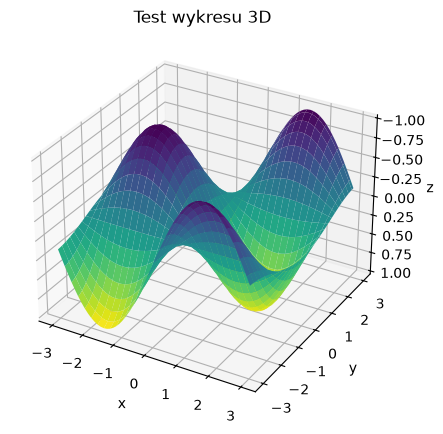

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Przygotowanie danych
x = np.linspace(-3, 3, 60)
X, Y = np.meshgrid(x, x)
Z = np.sin(X) * np.cos(Y)

# Tworzenie wykresu 3D
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

# Rysowanie powierzchni z mapą kolorów "viridis"
ax.plot_surface(X, Y, Z, cmap="viridis")

# Konfiguracja tytułu i etykiet osi
ax.set_title("Test wykresu 3D")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

# Odwrócenie osi Z, aby dopasować do widoku z obrazka (wartości ujemne na górze)
ax.invert_zaxis()

# Wyświetlenie wykresu
plt.show()
